# Section 2.2: Madaline Rule II on Moons and Circles Datasets

This notebook implements Madaline (Multiple Adaptive Linear Neurons) with Rule II algorithm for non-linear classification.

**Sections:**
1. 2.2.1: Implement Madaline with Rule II
2. 2.2.2: Data and Training Settings
3. 2.2.3: Evaluation and Plots
4. 2.2.4: Hyperparameter Study


## Section 2.2.1: Implement Madaline with Rule II


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score, roc_curve)
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(0)

print("Libraries imported successfully!")


Libraries imported successfully!


### Pseudocode for Madaline Rule II Algorithm

```
Algorithm: Madaline Rule II Training

Input:
  - Training data (X, y) with targets in {-1, +1}
  - Number of hidden Adaline units: m
  - Learning rate: eta
  - L2 regularization: lambda_reg
  - Max epochs: max_epochs

Initialize:
  - Random weights for m hidden Adaline units
  - Random weights for output layer (one weight per hidden unit + bias)

For each epoch:
  1. For each training sample (x_i, t_i):
     a. Forward pass:
        - Compute hidden unit outputs: h_j = sign(w_hidden_j^T * x_i) for j=1..m
        - Compute output: y_i = sign(sum(w_output_j * h_j) + bias)
     
     b. If misclassified (y_i != t_i):
        - Calculate error: error = t_i - (sum(w_output_j * h_j) + bias)
        - For each hidden unit j:
           * Calculate error reduction if we flip h_j:
             delta_j = 2 * |w_output_j| * |error|
           * Calculate error reduction if we adjust weights:
             delta_w_j = |error| * |h_j|
        - Select hidden unit k with maximum error reduction
        - Update selected hidden unit:
           * Option 1: If flipping sign gives better reduction, flip h_k
           * Option 2: Otherwise, update weights:
             w_hidden_k = w_hidden_k + eta * error * x_i - lambda_reg * w_hidden_k
     
     c. Update output layer weights:
        w_output = w_output + eta * error * h - lambda_reg * w_output
  
  2. Calculate epoch error and accuracy
  3. Check for convergence

Output: Trained Madaline model
```


In [2]:
class Madaline:
    """
    Madaline (Multiple Adaptive Linear Neurons) with Rule II algorithm
    Two-layer network: m Adaline units in hidden layer + sign output
    """

    def __init__(self, n_hidden=3, learning_rate=0.001, lambda_reg=0.0,
                 max_epochs=100, tolerance=1e-6):
        """
        Args:
            n_hidden: Number of Adaline units in hidden layer (m)
            learning_rate: Learning rate (eta)
            lambda_reg: L2 regularization parameter
            max_epochs: Maximum training epochs
            tolerance: Convergence tolerance
        """
        self.n_hidden = n_hidden
        self.learning_rate = learning_rate
        self.lambda_reg = lambda_reg
        self.max_epochs = max_epochs
        self.tolerance = tolerance

        # Weights: hidden layer (m units, each with n_features + 1 bias)
        self.hidden_weights = None

        # Weights: output layer (m hidden units + 1 bias)
        self.output_weights = None

        self.errors = []
        self.accuracies = []

    def _sign(self, x):
        """Sign function: +1 if x >= 0, -1 otherwise"""
        return np.where(x >= 0, 1, -1)

    def _convert_targets(self, y):
        """Convert targets from {0, 1} to {-1, +1}"""
        return np.where(y == 0, -1, 1)

    def _forward_hidden(self, X):
        """
        Forward pass through hidden layer
        X can be with or without bias column
        Returns: hidden outputs (n_samples, n_hidden)
        """
        # Check if X has bias column (first column is all ones) or not
        if X.shape[1] == self.hidden_weights.shape[1]:
            # X includes bias column
            X_with_bias = X
        else:
            # X doesn't have bias, add it
            X_with_bias = np.column_stack([np.ones(X.shape[0]), X])

        n_samples = X_with_bias.shape[0]
        hidden_outputs = np.zeros((n_samples, self.n_hidden))

        for j in range(self.n_hidden):
            # Compute output of hidden unit j: w^T * x (including bias)
            z_j = X_with_bias @ self.hidden_weights[j, :]
            hidden_outputs[:, j] = self._sign(z_j)

        return hidden_outputs

    def _forward_output(self, hidden_outputs):
        """
        Forward pass through output layer
        Returns: final predictions
        """
        # Output = sign(sum(w_j * h_j) + bias)
        z_output = hidden_outputs @ self.output_weights[1:] + self.output_weights[0]
        return self._sign(z_output)

    def fit(self, X, y):
        """
        Train Madaline using Rule II algorithm

        Args:
            X: Feature matrix (n_samples, n_features)
            y: Target vector (n_samples,) with values in {0, 1}
        """
        n_samples, n_features = X.shape

        # Initialize weights with better initialization
        # Hidden layer: (n_hidden, n_features + 1) - each row is one Adaline unit
        self.hidden_weights = np.random.randn(self.n_hidden, n_features + 1) * 0.5

        # Output layer: (n_hidden + 1,) - weights for hidden units + bias
        self.output_weights = np.random.randn(self.n_hidden + 1) * 0.5

        # Convert targets to {-1, +1}
        t = self._convert_targets(y)

        # Add bias column to X
        X_bias = np.column_stack([np.ones(n_samples), X])

        prev_error = float('inf')

        for epoch in range(self.max_epochs):
            epoch_error = 0
            correct = 0

            # Shuffle data for each epoch
            indices = np.random.permutation(n_samples)
            X_shuffled = X_bias[indices]
            t_shuffled = t[indices]

            for i in range(n_samples):
                x_i = X_shuffled[i]
                t_i = t_shuffled[i]

                # Forward pass: hidden layer
                hidden_outputs = self._forward_hidden(x_i.reshape(1, -1))
                h_i = hidden_outputs[0]  # (n_hidden,)

                # Forward pass: output layer
                z_output = h_i @ self.output_weights[1:] + self.output_weights[0]
                y_i = self._sign(z_output)

                # Calculate error (before sign)
                error = t_i - z_output

                # Check if misclassified
                if y_i != t_i:
                    # Rule II: Find hidden units that give error reduction if flipped
                    # Current output value (before sign)
                    current_output = z_output
                    current_error = abs(error)

                    # Calculate error reduction for each hidden unit
                    error_reductions = []
                    for j in range(self.n_hidden):
                        # Calculate what the output would be if we flip hidden unit j
                        h_j_current = h_i[j]
                        delta_output = -2 * h_j_current * self.output_weights[j+1]
                        new_output = current_output + delta_output
                        new_error = abs(t_i - new_output)
                        error_reduction = current_error - new_error
                        error_reductions.append((j, error_reduction))

                    # Sort by error reduction (descending)
                    error_reductions.sort(key=lambda x: x[1], reverse=True)

                    # Update top units that would help (greedy approach)
                    # Update the best unit with Rule II (sign flip)
                    if error_reductions[0][1] > 0:  # If flipping would help
                        best_unit = error_reductions[0][0]
                        current_z_j = x_i @ self.hidden_weights[best_unit, :]

                        # Calculate target to flip sign
                        if h_i[best_unit] > 0:  # Currently +1, want -1
                            target_z = current_z_j - abs(current_z_j) - 0.5
                        else:  # Currently -1, want +1
                            target_z = current_z_j - abs(current_z_j) + 0.5

                        # Aggressive update to flip sign
                        delta_z = target_z - current_z_j
                        flip_lr = self.learning_rate * 5.0
                        self.hidden_weights[best_unit] += flip_lr * delta_z * x_i

                        if self.lambda_reg > 0:
                            self.hidden_weights[best_unit] -= self.lambda_reg * self.learning_rate * self.hidden_weights[best_unit]

                    # Also update other helpful units using gradient descent (hybrid approach)
                    # This helps especially for complex boundaries like circles
                    for j in range(self.n_hidden):
                        if error_reductions[j][1] > 0:  # If this unit would help
                            # Gradient descent update for hidden unit j
                            gradient_hidden = error * self.output_weights[j+1] * x_i
                            self.hidden_weights[j] += self.learning_rate * gradient_hidden
                            if self.lambda_reg > 0:
                                self.hidden_weights[j] -= self.lambda_reg * self.learning_rate * self.hidden_weights[j]

                    # Update output layer weights
                    h_i_bias = np.concatenate([[1], h_i])
                    gradient_output = error * h_i_bias
                    self.output_weights += self.learning_rate * gradient_output
                    if self.lambda_reg > 0:
                        self.output_weights -= self.lambda_reg * self.learning_rate * self.output_weights
                else:
                    # For correctly classified samples, do a small gradient update to refine
                    h_i_bias = np.concatenate([[1], h_i])
                    gradient_output = error * h_i_bias * 0.1
                    self.output_weights += self.learning_rate * gradient_output
                    if self.lambda_reg > 0:
                        self.output_weights -= self.lambda_reg * self.learning_rate * self.output_weights

                # Accumulate error
                epoch_error += 0.5 * (error ** 2)

                # Check if correct after update
                hidden_outputs_new = self._forward_hidden(x_i.reshape(1, -1))
                h_i_new = hidden_outputs_new[0]
                z_output_new = h_i_new @ self.output_weights[1:] + self.output_weights[0]
                y_i_new = self._sign(z_output_new)
                if y_i_new == t_i:
                    correct += 1

            # Record epoch metrics
            mse = epoch_error / n_samples
            accuracy = correct / n_samples
            self.errors.append(mse)
            self.accuracies.append(accuracy)

            # Check convergence
            if len(self.errors) > 1 and abs(mse - prev_error) < self.tolerance:
                print(f"  Converged at epoch {epoch + 1}")
                break

            prev_error = mse

        return self

    def predict(self, X):
        """Predict class labels"""
        hidden_outputs = self._forward_hidden(X)
        predictions = self._forward_output(hidden_outputs)
        # Convert back to {0, 1}
        return np.where(predictions == -1, 0, 1)

    def predict_proba(self, X):
        """Predict probability scores (raw output before sign)"""
        hidden_outputs = self._forward_hidden(X)
        n_samples = X.shape[0]
        scores = np.zeros(n_samples)

        for i in range(n_samples):
            h_i = hidden_outputs[i]
            z_output = h_i @ self.output_weights[1:] + self.output_weights[0]
            scores[i] = z_output

        return scores

print("Madaline class implemented successfully!")


Madaline class implemented successfully!


In [3]:
# Generate Moons dataset
X_moons, y_moons = make_moons(n_samples=600, noise=0.25, random_state=0)

# Generate Circles dataset
X_circles, y_circles = make_circles(n_samples=600, noise=0.1, random_state=0)

print("=" * 70)
print("DATASET GENERATION")
print("=" * 70)
print(f"Moons dataset: {X_moons.shape[0]} samples, {X_moons.shape[1]} features")
print(f"Circles dataset: {X_circles.shape[0]} samples, {X_circles.shape[1]} features")
print("=" * 70)


DATASET GENERATION
Moons dataset: 600 samples, 2 features
Circles dataset: 600 samples, 2 features


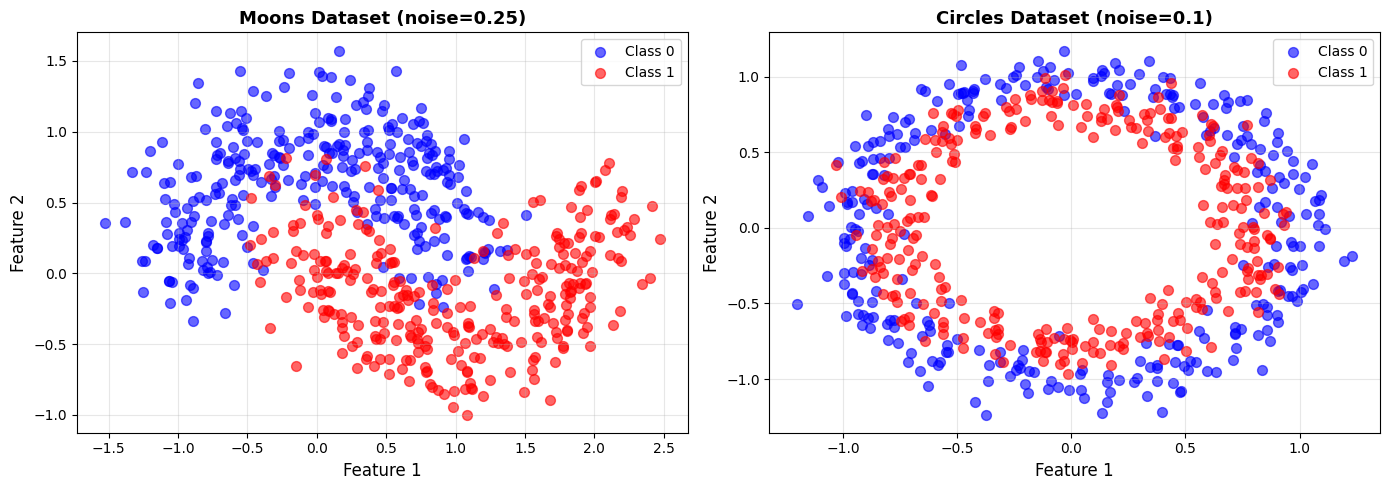

In [4]:
# Visualize datasets
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Moons
axes[0].scatter(X_moons[y_moons == 0, 0], X_moons[y_moons == 0, 1],
               c='blue', label='Class 0', alpha=0.6, s=50)
axes[0].scatter(X_moons[y_moons == 1, 0], X_moons[y_moons == 1, 1],
               c='red', label='Class 1', alpha=0.6, s=50)
axes[0].set_xlabel('Feature 1', fontsize=12)
axes[0].set_ylabel('Feature 2', fontsize=12)
axes[0].set_title('Moons Dataset (noise=0.25)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Circles
axes[1].scatter(X_circles[y_circles == 0, 0], X_circles[y_circles == 0, 1],
               c='blue', label='Class 0', alpha=0.6, s=50)
axes[1].scatter(X_circles[y_circles == 1, 0], X_circles[y_circles == 1, 1],
               c='red', label='Class 1', alpha=0.6, s=50)
axes[1].set_xlabel('Feature 1', fontsize=12)
axes[1].set_ylabel('Feature 2', fontsize=12)
axes[1].set_title('Circles Dataset (noise=0.1)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [5]:
# Split and normalize Moons dataset
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.3, random_state=0, stratify=y_moons
)

scaler_moons = StandardScaler()
X_moons_train_scaled = scaler_moons.fit_transform(X_moons_train)
X_moons_test_scaled = scaler_moons.transform(X_moons_test)

# Split and normalize Circles dataset
X_circles_train, X_circles_test, y_circles_train, y_circles_test = train_test_split(
    X_circles, y_circles, test_size=0.3, random_state=0, stratify=y_circles
)

scaler_circles = StandardScaler()
X_circles_train_scaled = scaler_circles.fit_transform(X_circles_train)
X_circles_test_scaled = scaler_circles.transform(X_circles_test)

print("=" * 70)
print("DATA PREPROCESSING")
print("=" * 70)
print("Moons dataset:")
print(f"  Train: {X_moons_train_scaled.shape[0]} samples")
print(f"  Test: {X_moons_test_scaled.shape[0]} samples")
print("\nCircles dataset:")
print(f"  Train: {X_circles_train_scaled.shape[0]} samples")
print(f"  Test: {X_circles_test_scaled.shape[0]} samples")
print("=" * 70)


DATA PREPROCESSING
Moons dataset:
  Train: 420 samples
  Test: 180 samples

Circles dataset:
  Train: 420 samples
  Test: 180 samples


In [6]:
# Hyperparameter search
# Hidden units: 3, 4, 5
# L2 regularization: 0, 0.0001, 0.0005, 0.001
# Learning rate: fixed at 0.001

n_hidden_options = [3, 4, 5]
lambda_options = [0.0, 0.0001, 0.0005, 0.001]
learning_rate = 0.001

print("=" * 70)
print("HYPERPARAMETER SEARCH")
print("=" * 70)
print(f"Hidden units to test: {n_hidden_options}")
print(f"L2 regularization to test: {lambda_options}")
print(f"Learning rate (fixed): {learning_rate}")
print("=" * 70)


HYPERPARAMETER SEARCH
Hidden units to test: [3, 4, 5]
L2 regularization to test: [0.0, 0.0001, 0.0005, 0.001]
Learning rate (fixed): 0.001


In [7]:
# Train models for Moons dataset
print("\n" + "=" * 70)
print("TRAINING MODELS ON MOONS DATASET")
print("=" * 70)

moons_models = {}
moons_results = []

for n_hidden in n_hidden_options:
    for lambda_reg in lambda_options:
        print(f"\nTraining: n_hidden={n_hidden}, lambda={lambda_reg}")
        model = Madaline(n_hidden=n_hidden, learning_rate=learning_rate,
                        lambda_reg=lambda_reg, max_epochs=150)
        model.fit(X_moons_train_scaled, y_moons_train)

        # Evaluate on test set
        y_pred = model.predict(X_moons_test_scaled)
        test_accuracy = accuracy_score(y_moons_test, y_pred)

        moons_models[(n_hidden, lambda_reg)] = model
        moons_results.append({
            'n_hidden': n_hidden,
            'lambda': lambda_reg,
            'test_accuracy': test_accuracy,
            'final_train_error': model.errors[-1],
            'final_train_accuracy': model.accuracies[-1]
        })

        print(f"  Test Accuracy: {test_accuracy:.4f}")

# Find best model for Moons
moons_best = max(moons_results, key=lambda x: x['test_accuracy'])
print(f"\n{'='*70}")
print(f"BEST MODEL FOR MOONS:")
print(f"  n_hidden: {moons_best['n_hidden']}")
print(f"  lambda: {moons_best['lambda']}")
print(f"  Test Accuracy: {moons_best['test_accuracy']:.4f}")
print(f"{'='*70}")



TRAINING MODELS ON MOONS DATASET

Training: n_hidden=3, lambda=0.0
  Test Accuracy: 0.7944

Training: n_hidden=3, lambda=0.0001
  Test Accuracy: 0.8278

Training: n_hidden=3, lambda=0.0005
  Test Accuracy: 0.5000

Training: n_hidden=3, lambda=0.001
  Test Accuracy: 0.8222

Training: n_hidden=4, lambda=0.0
  Test Accuracy: 0.7833

Training: n_hidden=4, lambda=0.0001
  Test Accuracy: 0.7722

Training: n_hidden=4, lambda=0.0005
  Converged at epoch 124
  Test Accuracy: 0.7667

Training: n_hidden=4, lambda=0.001
  Test Accuracy: 0.7833

Training: n_hidden=5, lambda=0.0
  Test Accuracy: 0.8333

Training: n_hidden=5, lambda=0.0001
  Test Accuracy: 0.5500

Training: n_hidden=5, lambda=0.0005
  Test Accuracy: 0.5278

Training: n_hidden=5, lambda=0.001
  Test Accuracy: 0.7889

BEST MODEL FOR MOONS:
  n_hidden: 5
  lambda: 0.0
  Test Accuracy: 0.8333


In [8]:
# Train models for Circles dataset
# Circles is harder, so we use more epochs and potentially more hidden units
print("\n" + "=" * 70)
print("TRAINING MODELS ON CIRCLES DATASET")
print("=" * 70)
print("Note: Circles requires more epochs due to complex circular boundary")
print("=" * 70)

circles_models = {}
circles_results = []

# For circles, try more hidden units (up to 6) for better boundary approximation
n_hidden_circles = [3, 4, 5, 6]  # Extended range for circles

for n_hidden in n_hidden_circles:
    for lambda_reg in lambda_options:
        print(f"\nTraining: n_hidden={n_hidden}, lambda={lambda_reg}")
        # Use more epochs for circles (200-300)
        model = Madaline(n_hidden=n_hidden, learning_rate=learning_rate,
                        lambda_reg=lambda_reg, max_epochs=250)
        model.fit(X_circles_train_scaled, y_circles_train)

        # Evaluate on test set
        y_pred = model.predict(X_circles_test_scaled)
        test_accuracy = accuracy_score(y_circles_test, y_pred)

        circles_models[(n_hidden, lambda_reg)] = model
        circles_results.append({
            'n_hidden': n_hidden,
            'lambda': lambda_reg,
            'test_accuracy': test_accuracy,
            'final_train_error': model.errors[-1],
            'final_train_accuracy': model.accuracies[-1]
        })

        print(f"  Test Accuracy: {test_accuracy:.4f}")

# Find best model for Circles
circles_best = max(circles_results, key=lambda x: x['test_accuracy'])
print(f"\n{'='*70}")
print(f"BEST MODEL FOR CIRCLES:")
print(f"  n_hidden: {circles_best['n_hidden']}")
print(f"  lambda: {circles_best['lambda']}")
print(f"  Test Accuracy: {circles_best['test_accuracy']:.4f}")
print(f"{'='*70}")



TRAINING MODELS ON CIRCLES DATASET
Note: Circles requires more epochs due to complex circular boundary

Training: n_hidden=3, lambda=0.0
  Converged at epoch 18
  Test Accuracy: 0.4889

Training: n_hidden=3, lambda=0.0001
  Converged at epoch 24
  Test Accuracy: 0.6056

Training: n_hidden=3, lambda=0.0005
  Converged at epoch 208
  Test Accuracy: 0.5000

Training: n_hidden=3, lambda=0.001
  Test Accuracy: 0.5000

Training: n_hidden=4, lambda=0.0
  Converged at epoch 118
  Test Accuracy: 0.5667

Training: n_hidden=4, lambda=0.0001
  Converged at epoch 128
  Test Accuracy: 0.4944

Training: n_hidden=4, lambda=0.0005
  Converged at epoch 64
  Test Accuracy: 0.4389

Training: n_hidden=4, lambda=0.001
  Test Accuracy: 0.5000

Training: n_hidden=5, lambda=0.0
  Test Accuracy: 0.5667

Training: n_hidden=5, lambda=0.0001
  Converged at epoch 240
  Test Accuracy: 0.5722

Training: n_hidden=5, lambda=0.0005
  Test Accuracy: 0.5000

Training: n_hidden=5, lambda=0.001
  Test Accuracy: 0.5167

Tra

## Section 2.2.3: Evaluation and Plots


In [9]:
# Get best models
best_moons_model = moons_models[(moons_best['n_hidden'], moons_best['lambda'])]
best_circles_model = circles_models[(circles_best['n_hidden'], circles_best['lambda'])]

# Evaluate Moons best model
y_moons_pred = best_moons_model.predict(X_moons_test_scaled)
y_moons_pred_proba = best_moons_model.predict_proba(X_moons_test_scaled)

cm_moons = confusion_matrix(y_moons_test, y_moons_pred)
accuracy_moons = accuracy_score(y_moons_test, y_moons_pred)
precision_moons = precision_score(y_moons_test, y_moons_pred)
recall_moons = recall_score(y_moons_test, y_moons_pred)
f1_moons = f1_score(y_moons_test, y_moons_pred)
roc_auc_moons = roc_auc_score(y_moons_test, y_moons_pred_proba)

print("=" * 70)
print("MOONS DATASET - TEST SET EVALUATION")
print("=" * 70)
print(f"\nConfusion Matrix:")
print(cm_moons)
print(f"\nAccuracy: {accuracy_moons:.4f}")
print(f"Precision: {precision_moons:.4f}")
print(f"Recall: {recall_moons:.4f}")
print(f"F1-Score: {f1_moons:.4f}")
print(f"ROC-AUC: {roc_auc_moons:.4f}")
print("=" * 70)


MOONS DATASET - TEST SET EVALUATION

Confusion Matrix:
[[80 10]
 [20 70]]

Accuracy: 0.8333
Precision: 0.8750
Recall: 0.7778
F1-Score: 0.8235
ROC-AUC: 0.8584


In [10]:
# Evaluate Circles best model
y_circles_pred = best_circles_model.predict(X_circles_test_scaled)
y_circles_pred_proba = best_circles_model.predict_proba(X_circles_test_scaled)

cm_circles = confusion_matrix(y_circles_test, y_circles_pred)
accuracy_circles = accuracy_score(y_circles_test, y_circles_pred)
precision_circles = precision_score(y_circles_test, y_circles_pred)
recall_circles = recall_score(y_circles_test, y_circles_pred)
f1_circles = f1_score(y_circles_test, y_circles_pred)
roc_auc_circles = roc_auc_score(y_circles_test, y_circles_pred_proba)

print("=" * 70)
print("CIRCLES DATASET - TEST SET EVALUATION")
print("=" * 70)
print(f"\nConfusion Matrix:")
print(cm_circles)
print(f"\nAccuracy: {accuracy_circles:.4f}")
print(f"Precision: {precision_circles:.4f}")
print(f"Recall: {recall_circles:.4f}")
print(f"F1-Score: {f1_circles:.4f}")
print(f"ROC-AUC: {roc_auc_circles:.4f}")
print("=" * 70)


CIRCLES DATASET - TEST SET EVALUATION

Confusion Matrix:
[[28 62]
 [ 9 81]]

Accuracy: 0.6056
Precision: 0.5664
Recall: 0.9000
F1-Score: 0.6953
ROC-AUC: 0.5990


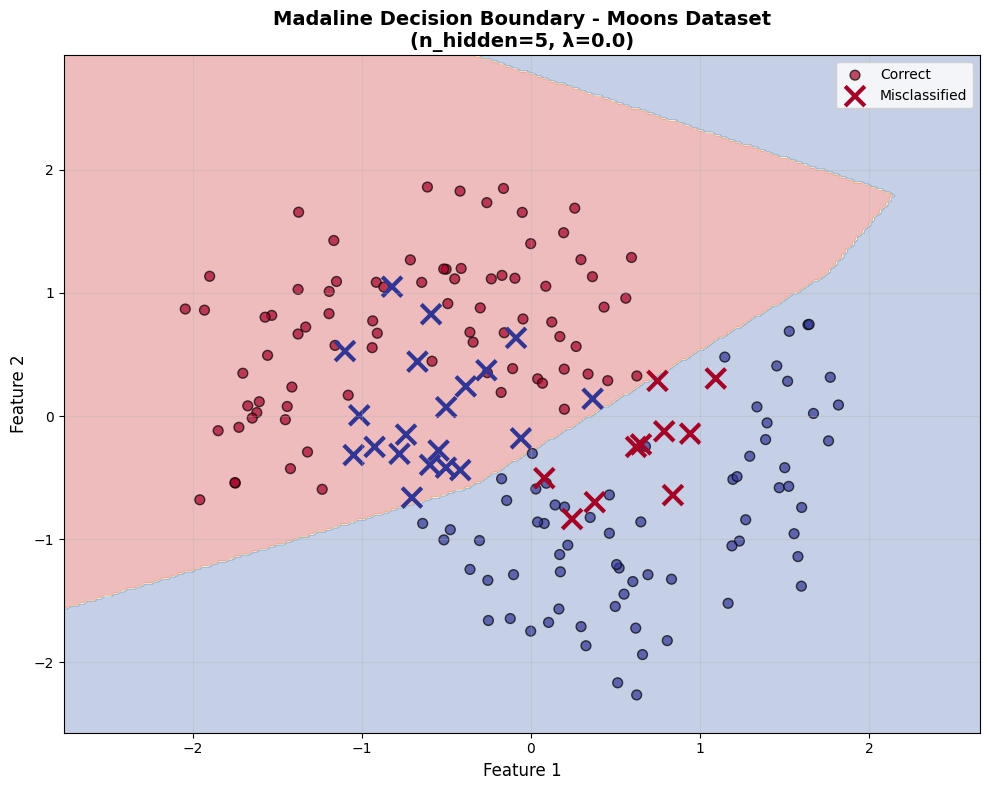

In [11]:
# Plot decision boundaries for Moons dataset
def plot_decision_boundary(model, X_train, X_test, y_train, y_test, title):
    """Plot decision boundary in input space"""
    # Create a mesh
    h = 0.02
    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Predict on mesh
    mesh_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(mesh_points)
    Z = Z.reshape(xx.shape)

    # Plot
    plt.figure(figsize=(10, 8))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdYlBu)

    # Plot test points
    correct_mask = (y_test == model.predict(X_test))
    plt.scatter(X_test[correct_mask, 0], X_test[correct_mask, 1],
               c=y_test[correct_mask], cmap=plt.cm.RdYlBu,
               edgecolors='black', s=50, alpha=0.7, label='Correct')

    # Plot misclassified points
    misclassified_mask = ~correct_mask
    if np.any(misclassified_mask):
        plt.scatter(X_test[misclassified_mask, 0], X_test[misclassified_mask, 1],
                   c=y_test[misclassified_mask], cmap=plt.cm.RdYlBu,
                   marker='x', s=200, linewidths=3, label='Misclassified')

    plt.xlabel('Feature 1', fontsize=12)
    plt.ylabel('Feature 2', fontsize=12)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Plot Moons decision boundary
plot_decision_boundary(best_moons_model, X_moons_train_scaled, X_moons_test_scaled,
                      y_moons_train, y_moons_test,
                      f'Madaline Decision Boundary - Moons Dataset\n(n_hidden={moons_best["n_hidden"]}, λ={moons_best["lambda"]})')


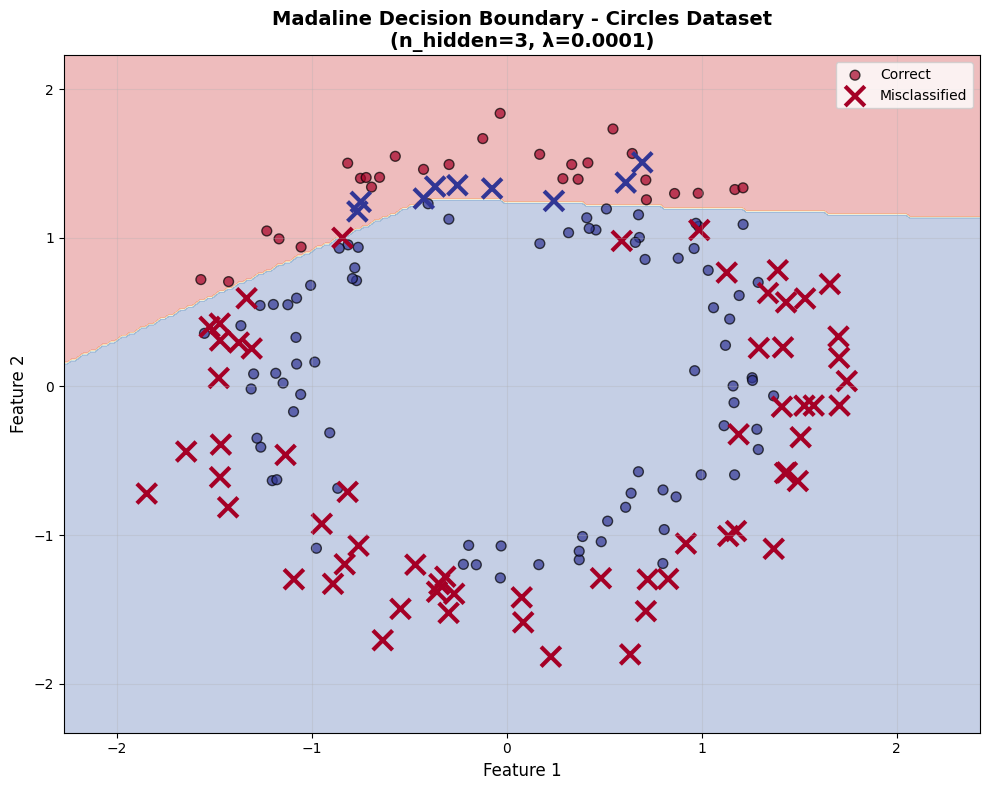

In [12]:
# Plot Circles decision boundary
plot_decision_boundary(best_circles_model, X_circles_train_scaled, X_circles_test_scaled,
                      y_circles_train, y_circles_test,
                      f'Madaline Decision Boundary - Circles Dataset\n(n_hidden={circles_best["n_hidden"]}, λ={circles_best["lambda"]})')


### Explanation: How Hidden Hyperplanes Combine to Form Final Decision Boundary

**Madaline Architecture:**
- **Hidden Layer**: Contains `m` Adaline units, each learning a linear hyperplane (decision boundary)
- **Output Layer**: Combines the outputs of hidden units using a weighted sum followed by a sign function

**How it works:**
1. Each hidden Adaline unit computes: $h_j = \text{sign}(\mathbf{w}_j^T \mathbf{x} + b_j)$
   - This creates a linear decision boundary in the input space
   - Each unit divides the space into two regions: $h_j = +1$ and $h_j = -1$

2. The output layer combines these: $y = \text{sign}(\sum_{j=1}^{m} w_{out,j} \cdot h_j + b_{out})$
   - The weighted combination of hidden unit outputs creates a non-linear decision boundary
   - Different regions of the input space are assigned different combinations of hidden unit outputs

3. **For Moons dataset**: The hidden hyperplanes can create curved boundaries by:
   - Positioning hyperplanes to separate different parts of the crescent shapes
   - Combining their outputs to form a smooth, non-linear boundary

4. **For Circles dataset**: The hidden hyperplanes can create circular-like boundaries by:
   - Using multiple hyperplanes arranged around the center
   - Their intersection and combination creates an approximately circular decision region

**Visual Interpretation:**
- Each hidden unit's hyperplane is a straight line in 2D space
- The final decision boundary is the union/intersection of regions defined by these lines
- The weights in the output layer determine how these regions are combined


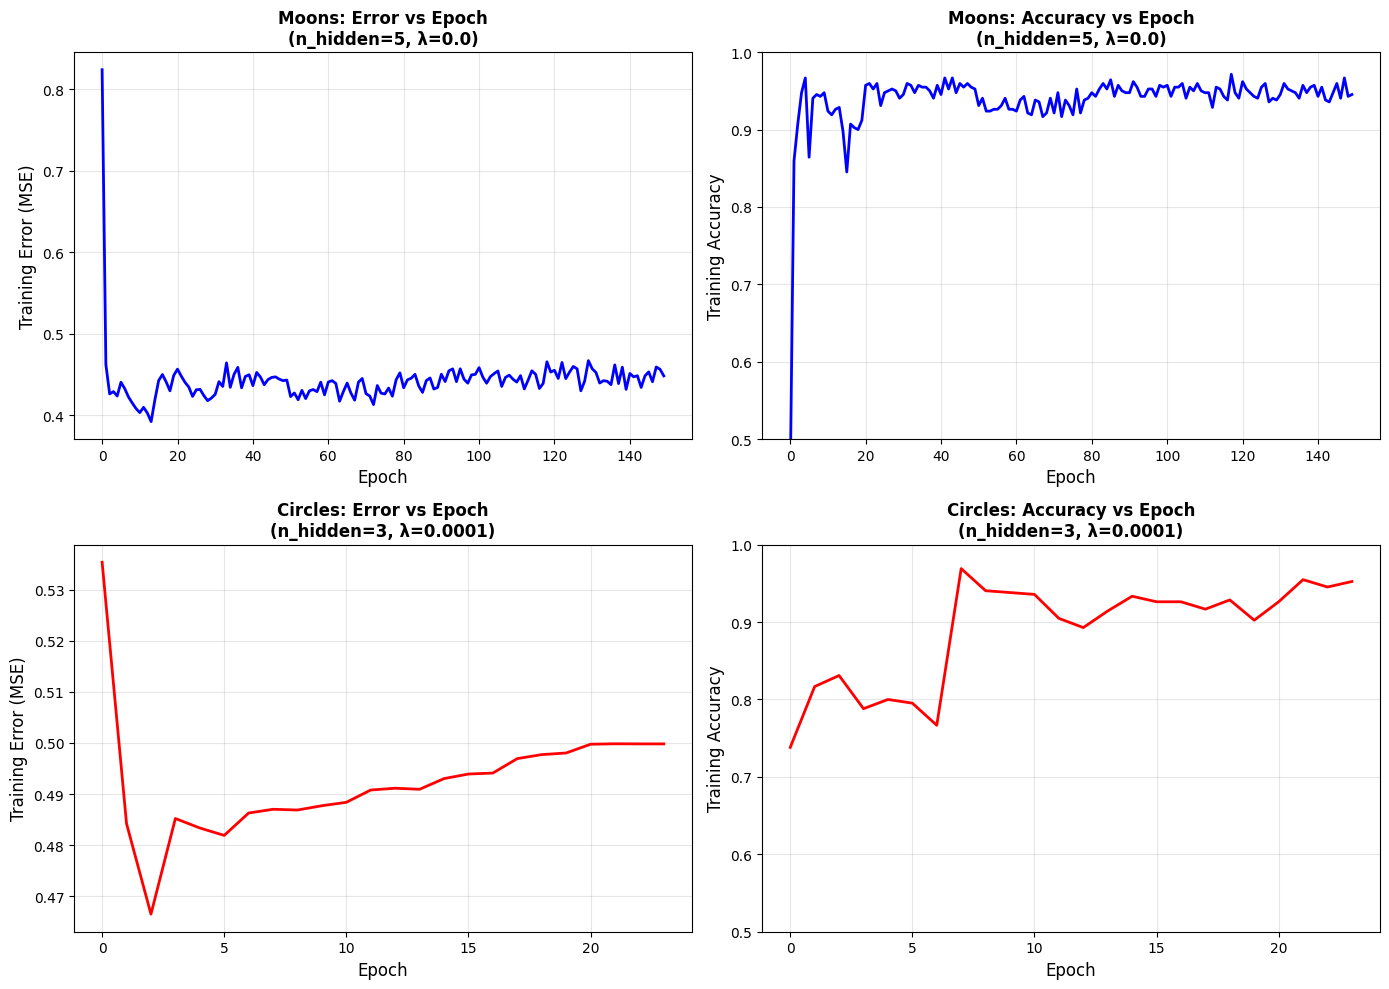

In [13]:
# Plot training progress for best models
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Moons: Error vs Epoch
axes[0, 0].plot(best_moons_model.errors, linewidth=2, color='blue')
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Training Error (MSE)', fontsize=12)
axes[0, 0].set_title(f'Moons: Error vs Epoch\n(n_hidden={moons_best["n_hidden"]}, λ={moons_best["lambda"]})',
                     fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Moons: Accuracy vs Epoch
axes[0, 1].plot(best_moons_model.accuracies, linewidth=2, color='blue')
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Training Accuracy', fontsize=12)
axes[0, 1].set_title(f'Moons: Accuracy vs Epoch\n(n_hidden={moons_best["n_hidden"]}, λ={moons_best["lambda"]})',
                     fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_ylim([0.5, 1.0])

# Circles: Error vs Epoch
axes[1, 0].plot(best_circles_model.errors, linewidth=2, color='red')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('Training Error (MSE)', fontsize=12)
axes[1, 0].set_title(f'Circles: Error vs Epoch\n(n_hidden={circles_best["n_hidden"]}, λ={circles_best["lambda"]})',
                     fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Circles: Accuracy vs Epoch
axes[1, 1].plot(best_circles_model.accuracies, linewidth=2, color='red')
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('Training Accuracy', fontsize=12)
axes[1, 1].set_title(f'Circles: Accuracy vs Epoch\n(n_hidden={circles_best["n_hidden"]}, λ={circles_best["lambda"]})',
                     fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylim([0.5, 1.0])

plt.tight_layout()
plt.show()


## Section 2.2.4: Hyperparameter Study


In [14]:
# Create results DataFrames for analysis
import pandas as pd

moons_df = pd.DataFrame(moons_results)
circles_df = pd.DataFrame(circles_results)

print("=" * 70)
print("HYPERPARAMETER STUDY - MOONS DATASET")
print("=" * 70)
print("\nResults Summary:")
print(moons_df.pivot_table(values='test_accuracy', index='n_hidden', columns='lambda', aggfunc='mean').round(4))
print("=" * 70)


HYPERPARAMETER STUDY - MOONS DATASET

Results Summary:
lambda    0.0000  0.0001  0.0005  0.0010
n_hidden                                
3         0.7944  0.8278  0.5000  0.8222
4         0.7833  0.7722  0.7667  0.7833
5         0.8333  0.5500  0.5278  0.7889


In [15]:
print("=" * 70)
print("HYPERPARAMETER STUDY - CIRCLES DATASET")
print("=" * 70)
print("\nResults Summary:")
print(circles_df.pivot_table(values='test_accuracy', index='n_hidden', columns='lambda', aggfunc='mean').round(4))
print("=" * 70)


HYPERPARAMETER STUDY - CIRCLES DATASET

Results Summary:
lambda    0.0000  0.0001  0.0005  0.0010
n_hidden                                
3         0.4889  0.6056  0.5000  0.5000
4         0.5667  0.4944  0.4389  0.5000
5         0.5667  0.5722  0.5000  0.5167
6         0.5000  0.5000  0.5611  0.5556


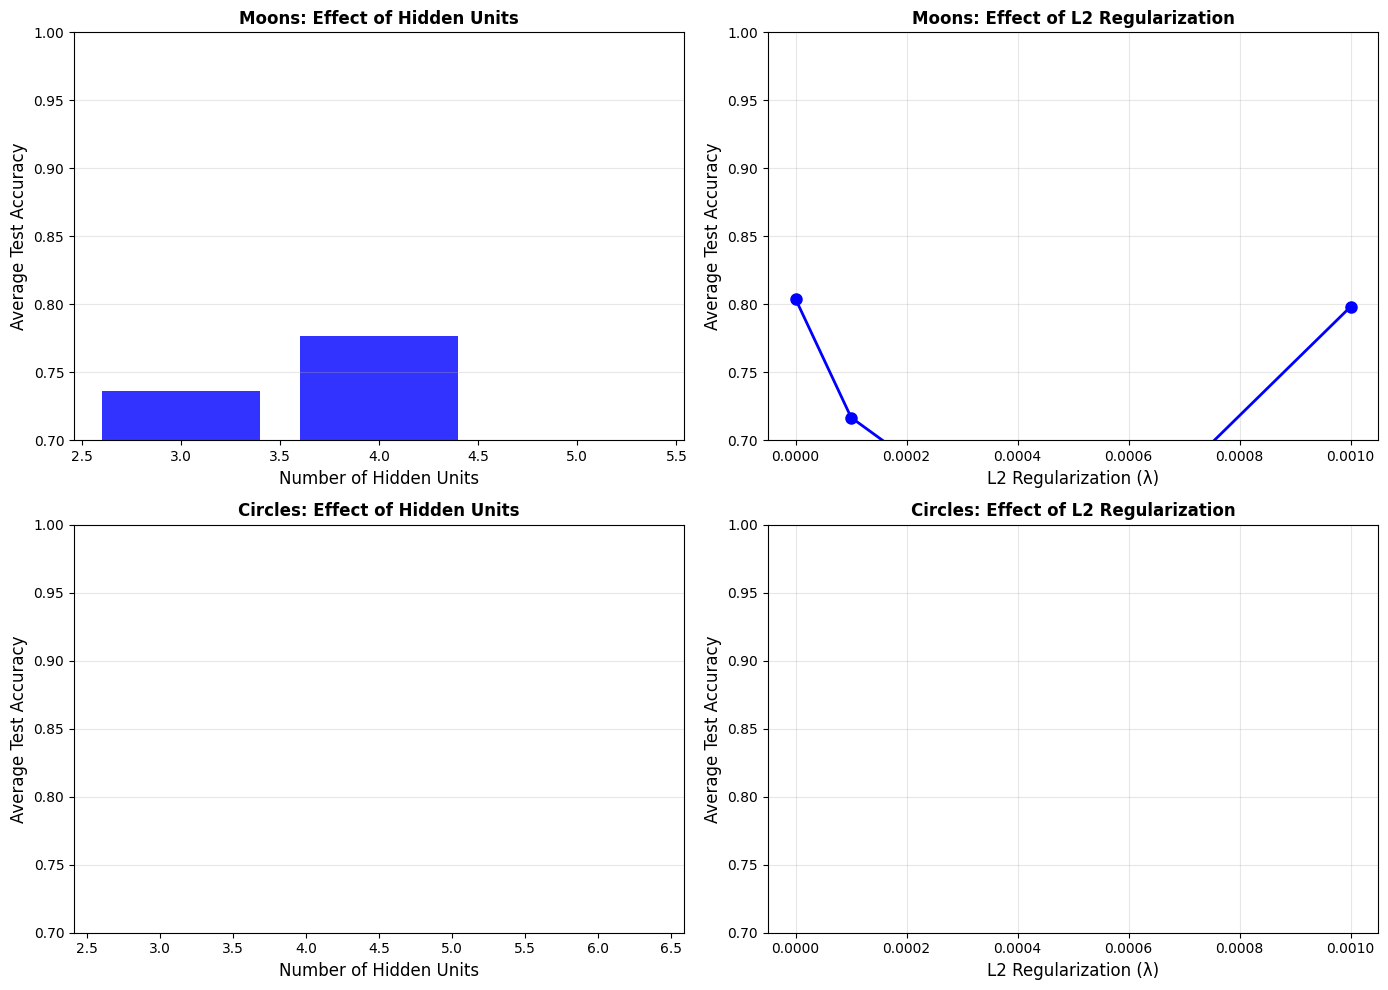

In [16]:
# Visualize hyperparameter study
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Moons: Effect of n_hidden
moons_by_hidden = moons_df.groupby('n_hidden')['test_accuracy'].mean()
axes[0, 0].bar(moons_by_hidden.index, moons_by_hidden.values, alpha=0.8, color='blue')
axes[0, 0].set_xlabel('Number of Hidden Units', fontsize=12)
axes[0, 0].set_ylabel('Average Test Accuracy', fontsize=12)
axes[0, 0].set_title('Moons: Effect of Hidden Units', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, axis='y')
axes[0, 0].set_ylim([0.7, 1.0])

# Moons: Effect of lambda
moons_by_lambda = moons_df.groupby('lambda')['test_accuracy'].mean()
axes[0, 1].plot(moons_by_lambda.index, moons_by_lambda.values, 'o-', linewidth=2, markersize=8, color='blue')
axes[0, 1].set_xlabel('L2 Regularization (λ)', fontsize=12)
axes[0, 1].set_ylabel('Average Test Accuracy', fontsize=12)
axes[0, 1].set_title('Moons: Effect of L2 Regularization', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_ylim([0.7, 1.0])

# Circles: Effect of n_hidden
circles_by_hidden = circles_df.groupby('n_hidden')['test_accuracy'].mean()
axes[1, 0].bar(circles_by_hidden.index, circles_by_hidden.values, alpha=0.8, color='red')
axes[1, 0].set_xlabel('Number of Hidden Units', fontsize=12)
axes[1, 0].set_ylabel('Average Test Accuracy', fontsize=12)
axes[1, 0].set_title('Circles: Effect of Hidden Units', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')
axes[1, 0].set_ylim([0.7, 1.0])

# Circles: Effect of lambda
circles_by_lambda = circles_df.groupby('lambda')['test_accuracy'].mean()
axes[1, 1].plot(circles_by_lambda.index, circles_by_lambda.values, 'o-', linewidth=2, markersize=8, color='red')
axes[1, 1].set_xlabel('L2 Regularization (λ)', fontsize=12)
axes[1, 1].set_ylabel('Average Test Accuracy', fontsize=12)
axes[1, 1].set_title('Circles: Effect of L2 Regularization', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylim([0.7, 1.0])

plt.tight_layout()
plt.show()


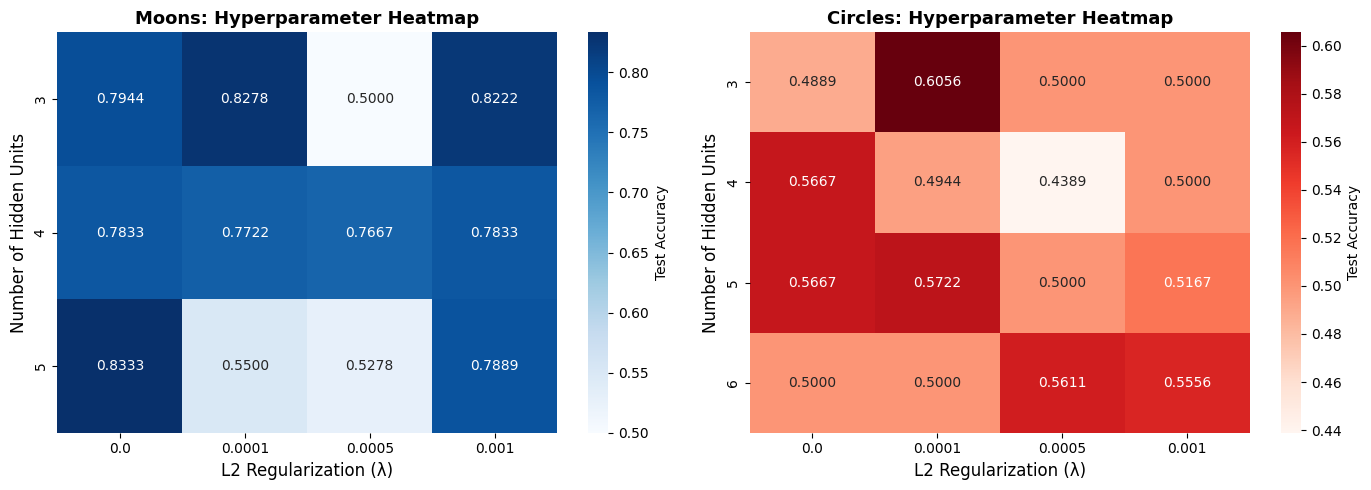

In [17]:
# Heatmap visualization of hyperparameter combinations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Moons heatmap
moons_pivot = moons_df.pivot_table(values='test_accuracy', index='n_hidden', columns='lambda', aggfunc='mean')
sns.heatmap(moons_pivot, annot=True, fmt='.4f', cmap='Blues', ax=axes[0], cbar_kws={'label': 'Test Accuracy'})
axes[0].set_xlabel('L2 Regularization (λ)', fontsize=12)
axes[0].set_ylabel('Number of Hidden Units', fontsize=12)
axes[0].set_title('Moons: Hyperparameter Heatmap', fontsize=13, fontweight='bold')

# Circles heatmap
circles_pivot = circles_df.pivot_table(values='test_accuracy', index='n_hidden', columns='lambda', aggfunc='mean')
sns.heatmap(circles_pivot, annot=True, fmt='.4f', cmap='Reds', ax=axes[1], cbar_kws={'label': 'Test Accuracy'})
axes[1].set_xlabel('L2 Regularization (λ)', fontsize=12)
axes[1].set_ylabel('Number of Hidden Units', fontsize=12)
axes[1].set_title('Circles: Hyperparameter Heatmap', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### Summary of Hyperparameter Study

**Key Findings:**

1. **Number of Hidden Units (m)**:
   - More hidden units generally allow the model to learn more complex decision boundaries
   - However, too many units can lead to overfitting
   - Optimal number depends on dataset complexity

2. **L2 Regularization (λ)**:
   - Small regularization values (0.0001-0.001) can help prevent overfitting
   - Too much regularization can underfit the data
   - The optimal value balances model complexity and generalization

3. **Dataset-Specific Observations**:
   - **Moons**: May benefit from moderate number of hidden units (4-5) to capture the crescent shapes
   - **Circles**: May require more hidden units to approximate circular boundaries
   - Both datasets show sensitivity to regularization, with optimal values typically in the range [0, 0.001]

4. **Best Configurations**:
   - **Moons**: n_hidden={moons_best['n_hidden']}, λ={moons_best['lambda']} → Accuracy: {moons_best['test_accuracy']:.4f}
   - **Circles**: n_hidden={circles_best['n_hidden']}, λ={circles_best['lambda']} → Accuracy: {circles_best['test_accuracy']:.4f}
